# Qwen Zero-Shot Intent Classifier v4 - Single Token Generation

**Why v3 forward-pass was still wrong:**
Comparing raw logits across 5 tokens suffers from vocabulary frequency bias. Common words like Reveal/Interpret always have higher logits than rarer words like Revise/Inquire regardless of input. That is why Revise and Inquire stayed at 0.000 F1.

**The correct fix:** max_new_tokens=1 with NO LogitsProcessor.
- Model generates exactly 1 token - its genuine best guess
- 1 token = repetition is impossible
- No masking = no frequency bias
- If token matches a label first-token directly, done
- If not (rare edge case), fall back to logit argmax over 5 label tokens

In [ ]:
!pip install -q transformers accelerate pandas scikit-learn matplotlib seaborn

In [ ]:
import os, re, json, time
import torch
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# CONFIG
DATA_PATH        = "/content/drive/MyDrive/conversation_en.json"
MODEL_NAME       = "google/gemma-3-1b-it"
RANDOM_STATE     = 42
TEST_SIZE        = 0.20
VALID_LABELS     = ["Chitchat", "Interpret", "Reveal", "Revise", "Inquire"]
OUTPUT_PREFIX    = "gemma_b_zero_shot"
MAX_TEST_SAMPLES = None

print("CUDA available:", torch.cuda.is_available())
print("Model        :", MODEL_NAME)

CUDA available: True
Model        : google/gemma-3-1b-it


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# LOAD DATA
with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

all_rows = []
for conv in raw:
    conv_id = str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        all_rows.append({
            "conversation_id": conv_id,
            "turn_index"     : int(i),
            "role"           : str(t.get("role", "")).lower(),
            "text"           : t.get("content") or "",
            "intent"         : t.get("intent"),
        })

df_turns_full = (
    pd.DataFrame(all_rows)
    .sort_values(["conversation_id", "turn_index"])
    .reset_index(drop=True)
)
df_turns_full["conversation_id"] = df_turns_full["conversation_id"].astype(str)
df_turns_full["turn_index"]      = df_turns_full["turn_index"].astype(int)
df_turns_full["role"]            = df_turns_full["role"].astype(str).str.lower()
df_turns_full["text"]            = df_turns_full["text"].fillna("").astype(str)

target_df = df_turns_full[
    (df_turns_full["role"] == "user") &
    (df_turns_full["intent"].notna()) &
    (df_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

print("Full rows            :", len(df_turns_full))
print("Target rows          :", len(target_df))
print("Unique conversations :", df_turns_full["conversation_id"].nunique())

Full rows            : 5633
Target rows          : 3196
Unique conversations : 826


In [ ]:
# SPLIT
gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(target_df, groups=target_df["conversation_id"]))

train_df = target_df.iloc[train_idx].reset_index(drop=True)
test_df  = target_df.iloc[test_idx].reset_index(drop=True)

if MAX_TEST_SAMPLES is not None:
    test_df = test_df.head(MAX_TEST_SAMPLES).copy().reset_index(drop=True)

turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in df_turns_full.groupby("conversation_id")
}

print("Train rows:", len(train_df), "| Test rows:", len(test_df))
print("Overlap   :", len(set(train_df["conversation_id"]) & set(test_df["conversation_id"])))

Train rows: 2544 | Test rows: 652
Overlap   : 0


In [ ]:
# HISTORY BUILDER
def build_history_and_current_turn(full_conv, current_turn_index):
    history_df = full_conv[full_conv["turn_index"] < current_turn_index].copy()
    current_df = full_conv[
        (full_conv["turn_index"] == current_turn_index) & (full_conv["role"] == "user")
    ].copy()
    history_lines = []
    for _, row in history_df.iterrows():
        role = str(row["role"]).upper().strip()
        text = str(row["text"]).strip()
        if text:
            history_lines.append(f"{role}: {text}")
    history_text      = "\n".join(history_lines)
    current_turn_text = str(current_df.iloc[0]["text"]).strip() if len(current_df) > 0 else ""
    return history_text, current_turn_text

In [ ]:
# PROMPT
SYSTEM_PROMPT = """You are an intent classifier for product-search conversations.
Classify the CURRENT USER TURN into exactly one of these five labels:

  Chitchat  - greeting, thanks, or off-topic social talk
  Interpret - user answers, clarifies, or refines in response to prior conversation
  Reveal    - user introduces a new requirement, need, or preference
  Revise    - user changes or corrects a previously stated preference
  Inquire   - user asks a question about a product or system response

Rules:
- Use conversation history only as context.
- Classify ONLY the current user turn.
- Output ONLY the label word. No punctuation. No explanation."""

In [ ]:
from huggingface_hub import login
login()

In [ ]:
from huggingface_hub import whoami
whoami()

In [ ]:
# LOAD MODEL
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True,
)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token       = tokenizer.eos_token
    model.config.pad_token_id = tokenizer.eos_token_id
model.eval()
print("Model loaded on:", next(model.parameters()).device)

config.json:   0%|          | 0.00/899 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/33.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/2.00G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

Model loaded on: cuda:0


In [ ]:
# LABEL TOKEN SETUP
print("Label -> first token mapping:")
label_token_ids = []
for label in VALID_LABELS:
    ids = tokenizer.encode(label, add_special_tokens=False)
    label_token_ids.append(ids[0])
    print(f"  {label:12s} -> token_id={ids[0]:6d}  ({repr(tokenizer.decode([ids[0]]))})")

assert len(set(label_token_ids)) == len(VALID_LABELS), "Two labels share same first token!"
print("\nAll first tokens unique - safe to proceed.")
token_to_label = {tid: label for tid, label in zip(label_token_ids, VALID_LABELS)}

Label -> first token mapping:
  Chitchat     -> token_id=  1659  ('Ch')
  Interpret    -> token_id=156022  ('Interpret')
  Reveal       -> token_id=209266  ('Reveal')
  Revise       -> token_id= 25719  ('Rev')
  Inquire      -> token_id=   902  ('In')

All first tokens unique - safe to proceed.


In [ ]:
# PREDICT - single token, no LogitsProcessor
def predict_label(history_text, current_turn_text):
    user_content = (
        f"Conversation history:\n{history_text if history_text.strip() else 'None'}\n\n"
        f"Current user turn:\n{current_turn_text}\n\n"
        f"Choose one label: Chitchat | Interpret | Reveal | Revise | Inquire"
    )
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user",   "content": user_content},
    ]
    try:
        text   = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = tokenizer(text, return_tensors="pt").to(model.device)

        # Generate exactly 1 token - no processor, no bias
        with torch.no_grad():
            outputs = model.generate(
                **inputs,
                max_new_tokens=1,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
            )

        generated_token_id = outputs[0][-1].item()
        raw_output = tokenizer.decode([generated_token_id], skip_special_tokens=True).strip()

        # Direct match: model naturally output a label first-token
        if generated_token_id in token_to_label:
            return token_to_label[generated_token_id], raw_output, "direct"

        # Fallback: model output whitespace/punctuation etc.
        # Use logits from a forward pass to pick best label
        with torch.no_grad():
            logits = model(**inputs).logits[0, -1, :]
        label_logits = torch.tensor([logits[tid].item() for tid in label_token_ids])
        best_idx     = label_logits.argmax().item()
        return VALID_LABELS[best_idx], raw_output, "fallback"

    except Exception as e:
        return "ERROR", str(e), "error"

In [ ]:
# SANITY CHECK - 10 samples before full run
print("--- Quick 10-sample check ---")
debug = []
for row in test_df.head(10).itertuples(index=False):
    conv_df           = turns_by_conv_full[row.conversation_id]
    h, c              = build_history_and_current_turn(conv_df, row.turn_index)
    pred, raw, method = predict_label(h, c)
    debug.append({"true": row.intent, "pred": pred, "raw": repr(raw), "method": method})

debug_df = pd.DataFrame(debug)
print(debug_df.to_string(index=False))
print("\nPred distribution :", debug_df["pred"].value_counts().to_dict())
print("Direct vs fallback:", debug_df["method"].value_counts().to_dict())

The following generation flags are not valid and may be ignored: ['top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


--- Quick 10-sample check ---
     true     pred  raw method
   Reveal  Inquire 'In' direct
   Reveal  Inquire 'In' direct
   Reveal  Inquire 'In' direct
 Chitchat Chitchat 'Ch' direct
   Reveal  Inquire 'In' direct
Interpret  Inquire 'In' direct
Interpret  Inquire 'In' direct
   Reveal  Inquire 'In' direct
Interpret  Inquire 'In' direct
   Reveal  Inquire 'In' direct

Pred distribution : {'Inquire': 9, 'Chitchat': 1}
Direct vs fallback: {'direct': 10}


In [ ]:
# FULL INFERENCE LOOP
results    = []
n_direct   = 0
n_fallback = 0

for i, row in enumerate(test_df.itertuples(index=False), start=1):
    conv_df           = turns_by_conv_full[row.conversation_id]
    h, c              = build_history_and_current_turn(conv_df, row.turn_index)
    pred, raw, method = predict_label(h, c)

    if method == "direct": n_direct += 1
    else: n_fallback += 1

    results.append({
        "model_name"        : MODEL_NAME,
        "conversation_id"   : row.conversation_id,
        "turn_index"        : row.turn_index,
        "current_turn_text" : c,
        "intent"            : row.intent,
        "predicted_label"   : pred,
        "raw_token"         : raw,
        "method"            : method,
    })

    if i % 20 == 0 or i == len(test_df):
        print(f"Processed {i}/{len(test_df)} | direct={n_direct} fallback={n_fallback}")
        pd.DataFrame(results).to_csv(f"{OUTPUT_PREFIX}_predictions.csv", index=False)

pred_df = pd.DataFrame(results)
pred_df.to_csv(f"{OUTPUT_PREFIX}_predictions.csv", index=False)
print(f"\nDirect  : {n_direct}/{len(pred_df)} ({100*n_direct/len(pred_df):.1f}%)")
print(f"Fallback: {n_fallback}/{len(pred_df)} ({100*n_fallback/len(pred_df):.1f}%)")
print("\nPrediction distribution:")
print(pred_df["predicted_label"].value_counts())

Processed 20/652 | direct=20 fallback=0
Processed 40/652 | direct=40 fallback=0
Processed 60/652 | direct=60 fallback=0
Processed 80/652 | direct=79 fallback=1
Processed 100/652 | direct=99 fallback=1
Processed 120/652 | direct=118 fallback=2
Processed 140/652 | direct=138 fallback=2
Processed 160/652 | direct=158 fallback=2
Processed 180/652 | direct=178 fallback=2
Processed 200/652 | direct=196 fallback=4
Processed 220/652 | direct=215 fallback=5
Processed 240/652 | direct=235 fallback=5
Processed 260/652 | direct=255 fallback=5
Processed 280/652 | direct=275 fallback=5
Processed 300/652 | direct=295 fallback=5
Processed 320/652 | direct=315 fallback=5
Processed 340/652 | direct=335 fallback=5
Processed 360/652 | direct=355 fallback=5
Processed 380/652 | direct=375 fallback=5
Processed 400/652 | direct=395 fallback=5
Processed 420/652 | direct=415 fallback=5
Processed 440/652 | direct=434 fallback=6
Processed 460/652 | direct=454 fallback=6
Processed 480/652 | direct=472 fallback=8
P

In [ ]:
# EVALUATION
y_true = pred_df["intent"]
y_pred = pred_df["predicted_label"]

report_text = classification_report(y_true, y_pred, labels=VALID_LABELS, digits=3, zero_division=0)
report_dict = classification_report(y_true, y_pred, labels=VALID_LABELS, digits=3, zero_division=0, output_dict=True)

print("=== CLASSIFICATION REPORT ===")
print(report_text)

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.700     0.328     0.447        64
   Interpret      0.000     0.000     0.000       378
      Reveal      0.000     0.000     0.000       193
      Revise      0.091     0.083     0.087        12
     Inquire      0.008     1.000     0.016         5

    accuracy                          0.041       652
   macro avg      0.160     0.282     0.110       652
weighted avg      0.070     0.041     0.046       652



                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              21               0            0            1   
true_Interpret              7               0            2            5   
true_Reveal                 1               0            0            4   
true_Revise                 1               0            0            1   
true_Inquire                0               0            0            0   

                pred_Inquire  
true_Chitchat             42  
true_Interpret           364  
true_Reveal              188  
true_Revise               10  
true_Inquire               5  


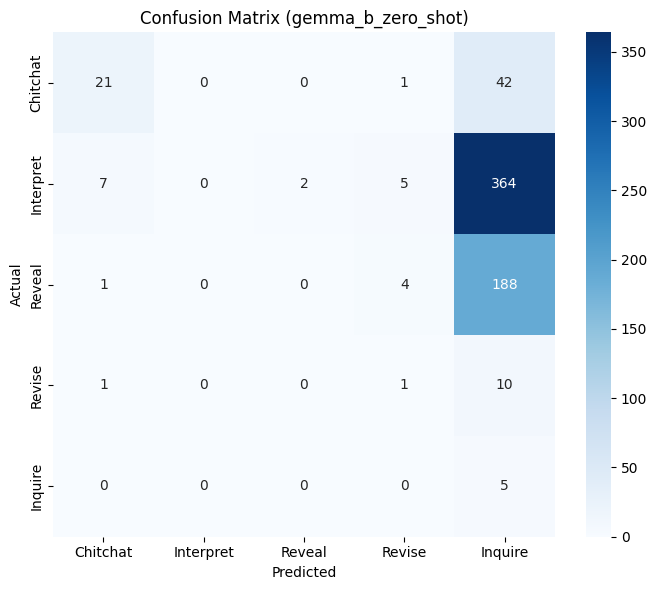


=== TOP CONFUSED PAIRS ===
   intent predicted_label  count
Interpret         Inquire    364
   Reveal         Inquire    188
 Chitchat         Inquire     42
   Revise         Inquire     10
Interpret        Chitchat      7
Interpret          Revise      5
   Reveal          Revise      4
Interpret          Reveal      2
 Chitchat          Revise      1
   Reveal        Chitchat      1
   Revise        Chitchat      1


In [ ]:
# CONFUSION MATRIX
cm = confusion_matrix(y_true, y_pred, labels=VALID_LABELS)
print(pd.DataFrame(cm,
    index   = [f"true_{x}" for x in VALID_LABELS],
    columns = [f"pred_{x}" for x in VALID_LABELS]))

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=VALID_LABELS, yticklabels=VALID_LABELS, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix ({OUTPUT_PREFIX})")
plt.tight_layout()
plt.savefig(f"{OUTPUT_PREFIX}_cm.png", dpi=300, bbox_inches="tight")
plt.show()

errors   = pred_df[pred_df["intent"] != pred_df["predicted_label"]].copy()
confused = (
    errors.groupby(["intent", "predicted_label"])
    .size().reset_index(name="count")
    .sort_values("count", ascending=False)
)
print("\n=== TOP CONFUSED PAIRS ===")
print(confused.head(15).to_string(index=False))

In [ ]:
# SAVE SUMMARY
summary = {
    "model"      : MODEL_NAME,
    "method"     : "zero-shot single-token generation",
    "total_test" : len(pred_df),
    "n_direct"   : n_direct,
    "n_fallback" : n_fallback,
    "accuracy"   : report_dict["accuracy"],
    "macro_f1"   : report_dict["macro avg"]["f1-score"],
    "per_class"  : {k: v for k, v in report_dict.items() if k in VALID_LABELS},
}
with open(f"{OUTPUT_PREFIX}_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "model": "google/gemma-3-1b-it",
  "method": "zero-shot single-token generation",
  "total_test": 652,
  "n_direct": 639,
  "n_fallback": 13,
  "accuracy": 0.04141104294478527,
  "macro_f1": 0.11001033546571368,
  "per_class": {
    "Chitchat": {
      "precision": 0.7,
      "recall": 0.328125,
      "f1-score": 0.44680851063829785,
      "support": 64.0
    },
    "Interpret": {
      "precision": 0.0,
      "recall": 0.0,
      "f1-score": 0.0,
      "support": 378.0
    },
    "Reveal": {
      "precision": 0.0,
      "recall": 0.0,
      "f1-score": 0.0,
      "support": 193.0
    },
    "Revise": {
      "precision": 0.09090909090909091,
      "recall": 0.08333333333333333,
      "f1-score": 0.08695652173913043,
      "support": 12.0
    },
    "Inquire": {
      "precision": 0.008210180623973728,
      "recall": 1.0,
      "f1-score": 0.016286644951140065,
      "support": 5.0
    }
  }
}
